# Figure S9: JUMP-Enamine and HTS Tanimoto Similarity Distribution Shift

Compares Tanimoto similarity distributions between the JUMP library and external compound sources (Enamine and gProbe HTS) to assess distribution shift.

This notebook generates density plots comparing Tanimoto similarity distributions:
1. Enamine compounds vs. JUMP compounds
2. HTS (gProbe) compounds vs. JUMP compounds, per drug target (PI3K, HDAC, MAPK, JAK)

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

# --- Output directories ---
BASE_DIR = str(REPO_ROOT)
DATA_DIR = os.path.join(BASE_DIR, "data", "jump_enamine_similarities")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "jump_enamine_similarities")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

setup_publication_style(BASE_DIR)

FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

FORCE_RECOMPUTE = False

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'haiku'
Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Load Pre-computed Tanimoto Similarities

In [2]:
enamine_jump_max_ts = np.loadtxt(os.path.join(FINAL_DATA_DIR, "library_similarities/max_tanimoto_similarities.enamine_jump.txt"))
jump_jump_max_ts = np.loadtxt(os.path.join(FINAL_DATA_DIR, "library_similarities/max_tanimoto_similarities.jump_jump.txt"))
enamine_enamine_max_ts = np.loadtxt(os.path.join(FINAL_DATA_DIR, "library_similarities/max_tanimoto_similarities.enamine_enamine.txt"))

hts_hts_ts_dict = {}
hts_jump_ts_dict = {}
for drug_target in ["pi3k", "hdac", "jak"]:
    hts_jump_ts_dict[drug_target] = np.loadtxt(os.path.join(FINAL_DATA_DIR, f"library_similarities/max_tanimoto_similarities.hts_jump.{drug_target}.txt"))
    hts_hts_ts_dict[drug_target] = np.loadtxt(os.path.join(FINAL_DATA_DIR, f"library_similarities/max_tanimoto_similarities.hts_hts.{drug_target}.txt"))

Figure already exists


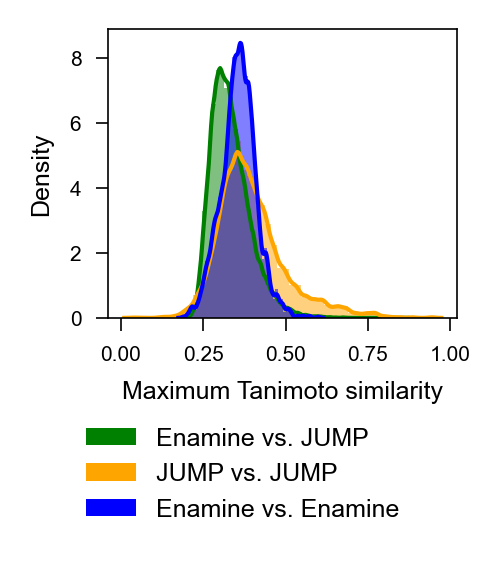

In [3]:
plt.figure(figsize=(1.5,1.25))
plt.hist(enamine_jump_max_ts,bins=50,alpha=0.5,color="green",density=True,label="Enamine vs. JUMP")
plt.hist(jump_jump_max_ts,bins=50,alpha=0.5,color="orange",density=True,label="JUMP vs. JUMP")
plt.hist(enamine_enamine_max_ts,bins=50,alpha=0.5,color="blue",density=True,label="Enamine vs. Enamine")

sns.kdeplot(enamine_jump_max_ts,bw_adjust=0.5,color="green",linewidth=1)
sns.kdeplot(jump_jump_max_ts,bw_adjust=0.5,color="orange",linewidth=1)
sns.kdeplot(enamine_enamine_max_ts,bw_adjust=0.5,color="blue",linewidth=1)

plt.xlabel("Maximum Tanimoto similarity")
plt.ylabel("Density")

# legend alpha
leg = plt.legend(bbox_to_anchor=(0.9, -0.3)) # , loc='upper left', borderaxespad=0.)
for lh in leg.legendHandles:
    lh.set_alpha(1)

fig_path = os.path.join(FIGURE_DIR, "FigS9_enamine_jump_tanimoto_similarities.pdf")
save_figure(fig_path, FORCE_RECOMPUTE)

Figure already exists


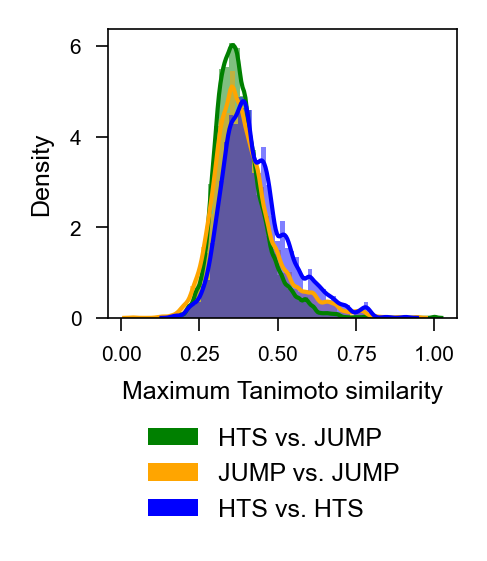

Figure already exists


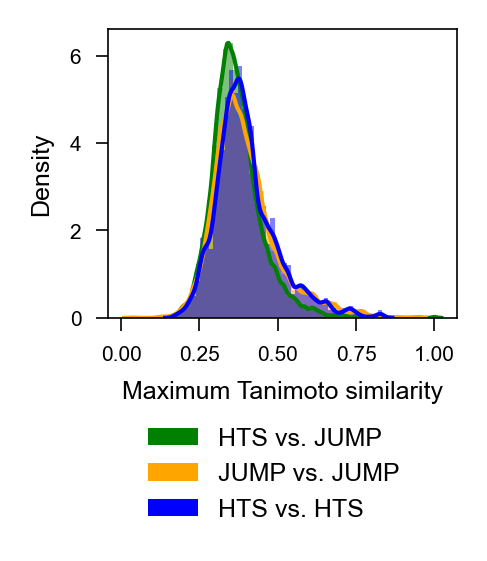

Figure already exists


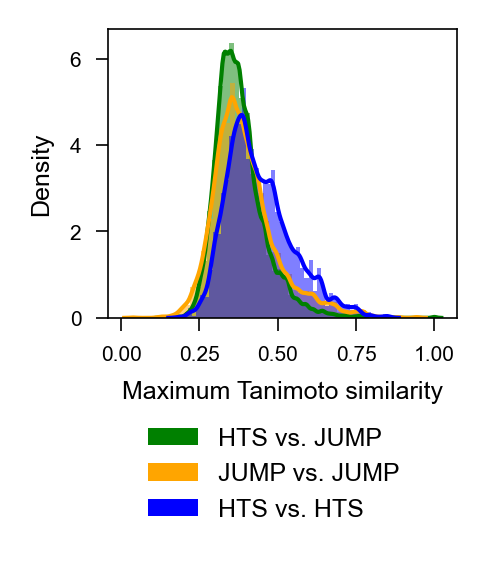

In [4]:
for drug_target in ["pi3k", "hdac", "jak"]:
    hts_jump_max_ts = hts_jump_ts_dict[drug_target]
    hts_hts_max_ts = hts_hts_ts_dict[drug_target]

    plt.figure(figsize=(1.5,1.25))
    plt.hist(hts_jump_max_ts,bins=50,alpha=0.5,color="green",density=True,label="HTS vs. JUMP")
    plt.hist(jump_jump_max_ts,bins=50,alpha=0.5,color="orange",density=True,label="JUMP vs. JUMP")
    plt.hist(hts_hts_max_ts,bins=50,alpha=0.5,color="blue",density=True,label="HTS vs. HTS")

    sns.kdeplot(hts_jump_max_ts,bw_adjust=0.5,color="green",linewidth=1)
    sns.kdeplot(jump_jump_max_ts,bw_adjust=0.5,color="orange",linewidth=1)
    sns.kdeplot(hts_hts_max_ts,bw_adjust=0.5,color="blue",linewidth=1)

    plt.xlabel("Maximum Tanimoto similarity")
    plt.ylabel("Density")

    leg = plt.legend(bbox_to_anchor=(0.9, -0.3))
    for lh in leg.legendHandles:
        lh.set_alpha(1)

    fig_path = os.path.join(FIGURE_DIR, "FigS8_hts_jump_tanimoto_similarities_{}.pdf".format(drug_target))
    save_figure(fig_path, FORCE_RECOMPUTE)

In [5]:
enamine_df = pd.DataFrame({
    "max_tanimoto_similarity": np.concatenate([enamine_jump_max_ts, jump_jump_max_ts, enamine_enamine_max_ts]),
    "comparison_type": (
        ["Enamine vs JUMP"] * len(enamine_jump_max_ts)
        + ["JUMP vs JUMP"] * len(jump_jump_max_ts)
        + ["Enamine vs Enamine"] * len(enamine_enamine_max_ts)
    ),
})
save_figure_data(
    enamine_df,
    os.path.join(FIGURE_DIR, "FigS9_enamine_jump_tanimoto_similarities_data.tsv"),
    FORCE_RECOMPUTE,
)

for drug_target in ["pi3k", "hdac", "jak"]:
    hts_df = pd.DataFrame({
        "max_tanimoto_similarity": np.concatenate([
            hts_jump_ts_dict[drug_target], jump_jump_max_ts, hts_hts_ts_dict[drug_target],
        ]),
        "comparison_type": (
            ["HTS vs JUMP"] * len(hts_jump_ts_dict[drug_target])
            + ["JUMP vs JUMP"] * len(jump_jump_max_ts)
            + ["HTS vs HTS"] * len(hts_hts_ts_dict[drug_target])
        ),
    })
    save_figure_data(
        hts_df,
        os.path.join(FIGURE_DIR, f"FigS8_hts_jump_tanimoto_similarities_{drug_target}_data.tsv"),
        FORCE_RECOMPUTE,
    )

Figure data already exists
Figure data already exists
Figure data already exists
Figure data already exists
